## **1. data**

In [1]:
!pip install pandas numpy matplotlib yfinance PyPortfolioOpt
import os
if not os.path.isdir('data'):
    os.system('git clone https://github.com/robertmartin8/PyPortfolioOpt.git')
    os.chdir('PyPortfolioOpt/cookbook')

In [2]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
tickers = ["MSFT", "AMZN", "KO", "MA", "COST",
           "LUV", "XOM", "PFE", "JPM", "UNH",
           "ACN", "DIS", "GILD", "F", "TSLA"]

In [4]:
ohlc = yf.download(tickers, period="max")

[*********************100%%**********************]  15 of 15 completed


In [5]:
prices = ohlc["Adj Close"].dropna(how="all")
prices.tail()

Ticker,ACN,AMZN,COST,DIS,F,GILD,JPM,KO,LUV,MA,MSFT,PFE,TSLA,UNH,XOM
Date,,,,,,,,,,,,,,,
2024-07-22,331.510010,182.550003,846.215271,94.129997,14.12,72.410004,210.279999,64.769997,27.660000,447.940002,442.940002,29.188072,251.509995,558.530029,115.269997
2024-07-23,330.329987,186.410004,850.898621,90.940002,13.83,71.169998,210.330002,64.959999,27.180000,441.720001,444.850006,29.089464,246.380005,554.700012,113.410004
2024-07-24,328.679993,180.830002,829.638916,89.800003,13.67,73.500000,208.589996,65.809998,26.610001,432.450012,428.899994,29.562782,215.990005,559.750000,115.010002
2024-07-25,330.119995,179.850006,814.790039,89.209999,11.16,76.510002,208.669998,66.070000,28.080000,429.600006,418.399994,29.760000,220.250000,559.679993,117.430000
2024-07-26,328.459991,182.500000,817.599976,89.930000,11.19,77.010002,212.240005,67.050003,27.230000,438.179993,425.269989,30.770000,219.800003,569.719971,117.330002


<Axes: xlabel='Date'>

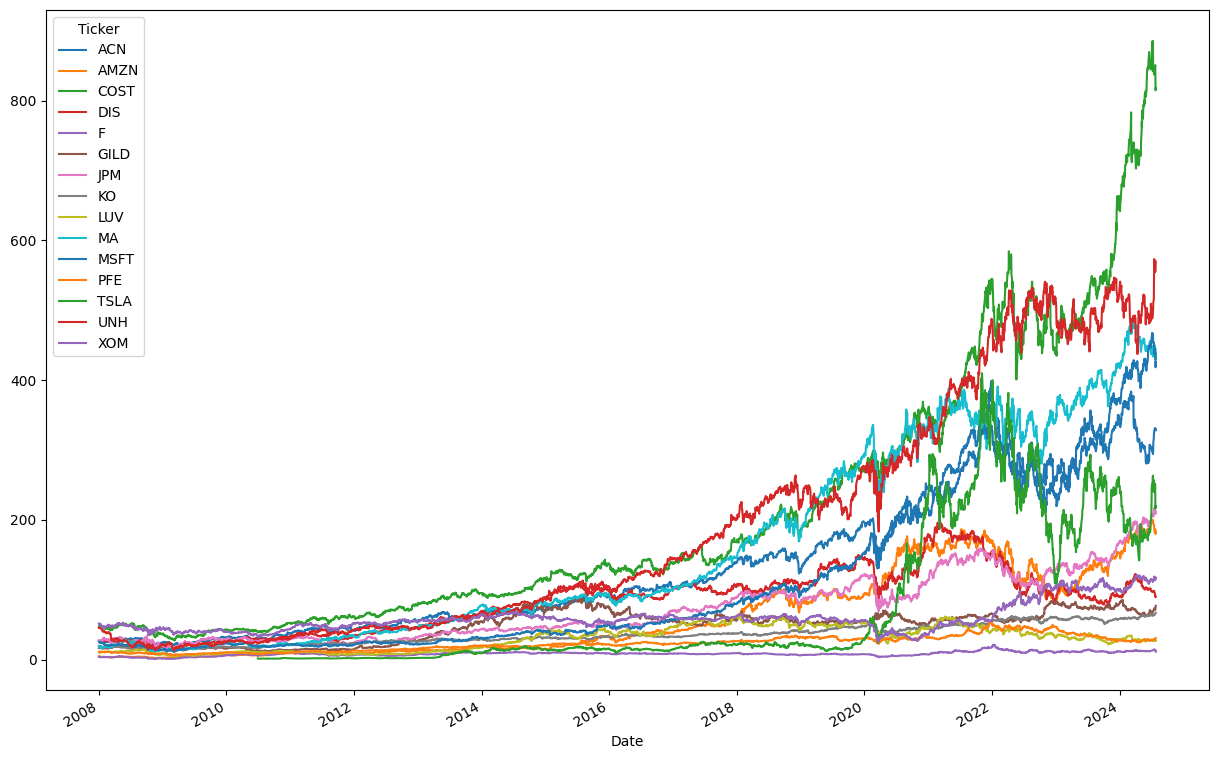

In [6]:
prices[prices.index >= "2008-01-01"].plot(figsize=(15,10))

## **2. cvxopt with random data**

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import cvxopt as opt
from cvxopt import blas, solvers
import pandas as pd

np.random.seed(123)

# Turn off progress printing
solvers.options['show_progress'] = False

In [8]:
## NUMBER OF ASSETS
n_assets = 4

## NUMBER OF OBSERVATIONS
n_obs = 1000

return_vec = np.random.randn(n_assets, n_obs)
print(np.shape(return_vec))

(4, 1000)


Text(0, 0.5, 'returns')

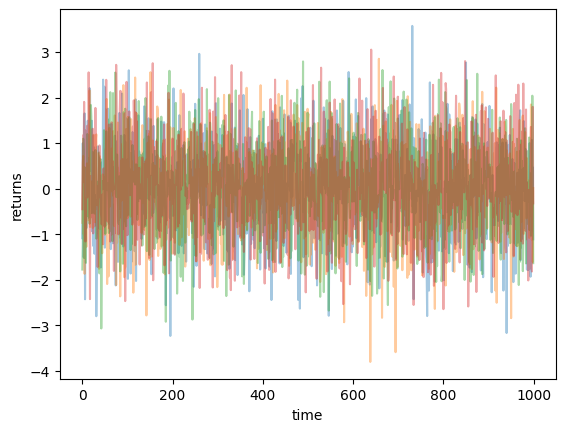

In [9]:
plt.plot(return_vec.T, alpha=.4);
plt.xlabel('time')
plt.ylabel('returns')

In [10]:
def rand_weights(n):
    ''' Produces n random weights that sum to 1 '''
    k = np.random.rand(n)
    return k / sum(k)

print(rand_weights(n_assets))
print(rand_weights(n_assets))

[0.54066805 0.2360283  0.11660484 0.1066988 ]
[0.27638339 0.03006307 0.47850085 0.21505269]


In [11]:
def random_portfolio(returns):
    '''
    Returns the mean and standard deviation of returns for a random portfolio
    '''

    p = np.asmatrix(np.mean(returns, axis=1))
    w = np.asmatrix(rand_weights(returns.shape[0]))
    C = np.asmatrix(np.cov(returns))

    mu = w * p.T
    # sigma = np.sqrt(w * C * w.T)
    sigma = w * C * w.T

    # This recursion reduces outliers to keep plots pretty
    if sigma > 2:
        return random_portfolio(returns)
    return mu, sigma

In [12]:
n_portfolios = 500
means, stds = np.column_stack([
    random_portfolio(return_vec)
    for _ in range(n_portfolios)
])
sharpes = means / np.sqrt(stds)

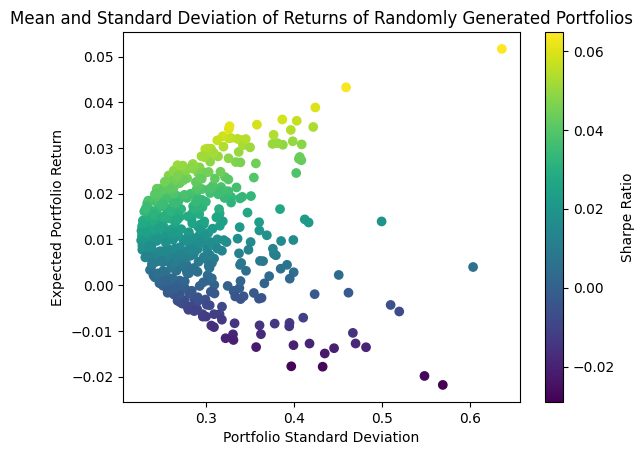

In [13]:
# Create the scatter plot
plt.scatter(stds, means, c=sharpes)

# Add labels and title
plt.xlabel('Portfolio Standard Deviation')
plt.ylabel('Expected Portfolio Return')
plt.title('Mean and Standard Deviation of Returns of Randomly Generated Portfolios')

# Add a colorbar
cbar = plt.colorbar()
cbar.set_label('Sharpe Ratio')

# Show the plot
plt.show()

In [14]:
def optimal_portfolio(returns):
    n = len(returns)
    returns = np.asmatrix(returns)

    N = 100
    mus = [10**(5.0 * t/N - 1.0) for t in range(N)]
    print(np.shape(mus))

    # Convert to cvxopt matrices
    S = opt.matrix(np.cov(returns))
    pbar = opt.matrix(np.mean(returns, axis=1))

    # Create constraint matrices
    G = -opt.matrix(np.eye(n))   # negative n x n identity matrix
    h = opt.matrix(0.0, (n ,1))
    A = opt.matrix(1.0, (1, n))
    b = opt.matrix(1.0)

    # Calculate efficient frontier weights using quadratic programming
    import time
    start_time = time.time()  # Start timing
    portfolios = [solvers.qp(mu*S, -pbar, G, h, A, b)['x']
                  for mu in mus]
    end_time = time.time()  # End timing
    elapsed_time = (end_time - start_time) / N  # Calculate elapsed time
    print(f"Time to solve: {elapsed_time:.4f} seconds")
    print(np.shape(portfolios))

    ## CALCULATE RISKS AND REWARDS FS FRONTIER
    rewards = [blas.dot(pbar, x) for x in portfolios]
    # risks = [np.sqrt(blas.dot(x, S*x)) for x in portfolios]
    risks = [blas.dot(x, S*x) for x in portfolios]
    print(np.shape(rewards))
    print(np.shape(risks))

    sharpes = rewards / np.sqrt(risks)
    print(np.shape(sharpes))

    # ## CALCULATE THE 2ND DEGREE POLYNOMIAL OF THE FRONTIER CURVE
    # m1 = np.polyfit(rewards, risks, 2)
    # x1 = np.sqrt(m1[2] / m1[0])

    # # CALCULATE THE OPTIMAL PORTFOLIO
    # wt = solvers.qp(opt.matrix(x1 * S), -pbar, G, h, A, b)['x']

    # return np.asarray(wt), rewards, risks
    return rewards, risks, sharpes, portfolios

In [15]:
# weights, rewards, risks = optimal_portfolio(return_vec)
rewards, risks, sharpes_optim, portfolios = optimal_portfolio(return_vec)

(100,)
Time to solve: 0.0019 seconds
(100, 4, 1)
(100,)
(100,)
(100,)


In [16]:
sharpes.max()

0.06478739202050542

In [17]:
sharpes_optim.max()

0.06883089112477477

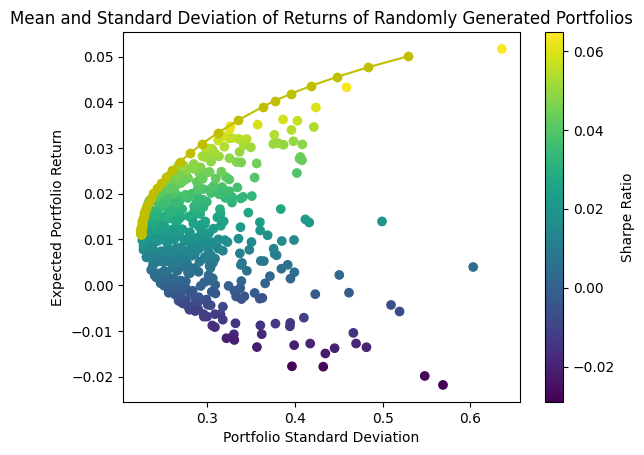

In [18]:
# Create the scatter plot
plt.scatter(stds, means, c=sharpes)
plt.plot(risks, rewards, 'y-o')

# Add labels and title
plt.xlabel('Portfolio Standard Deviation')
plt.ylabel('Expected Portfolio Return')
plt.title('Mean and Standard Deviation of Returns of Randomly Generated Portfolios')

# Add a colorbar
cbar = plt.colorbar()
cbar.set_label('Sharpe Ratio')

# Show the plot
plt.show()

## **3. backtesting on real market data**

In [19]:
tickers = ["MSFT", "AMZN", "KO", "MA", "COST",
           "LUV", "XOM", "PFE", "JPM", "UNH",
           "ACN", "DIS", "GILD", "F", "TSLA"]
ohlc = yf.download(tickers, start="2014-01-01", end="2019-01-01")

[*********************100%%**********************]  15 of 15 completed


In [20]:
prices = ohlc["Adj Close"].dropna(how="all")
prices.head()

Ticker,ACN,AMZN,COST,DIS,F,GILD,JPM,KO,LUV,MA,MSFT,PFE,TSLA,UNH,XOM
Date,,,,,,,,,,,,,,,
2014-01-02,67.322578,19.898500,94.494576,69.643204,9.181994,54.670723,43.550617,29.140572,17.104061,78.087723,31.176825,19.114635,10.006667,63.479286,63.764240
2014-01-03,67.546638,19.822001,94.077477,69.497101,9.223626,54.023762,43.887283,28.997250,17.593267,77.775963,30.967068,19.152290,9.970667,63.930431,63.610821
2014-01-06,66.833000,19.681499,93.363617,69.232300,9.265252,53.238705,44.141670,28.861078,17.348663,77.390282,30.312668,19.171122,9.800000,63.198322,63.706696
2014-01-07,67.646217,19.901501,92.930458,69.707108,9.146315,52.904339,43.632912,28.947075,17.692917,78.468300,30.547590,19.290350,9.957333,65.130730,64.608055
2014-01-08,68.169006,20.096001,91.478706,68.684441,9.241467,53.398640,44.044399,28.624559,18.281776,78.444862,30.002247,19.422131,10.085333,64.373093,64.397087


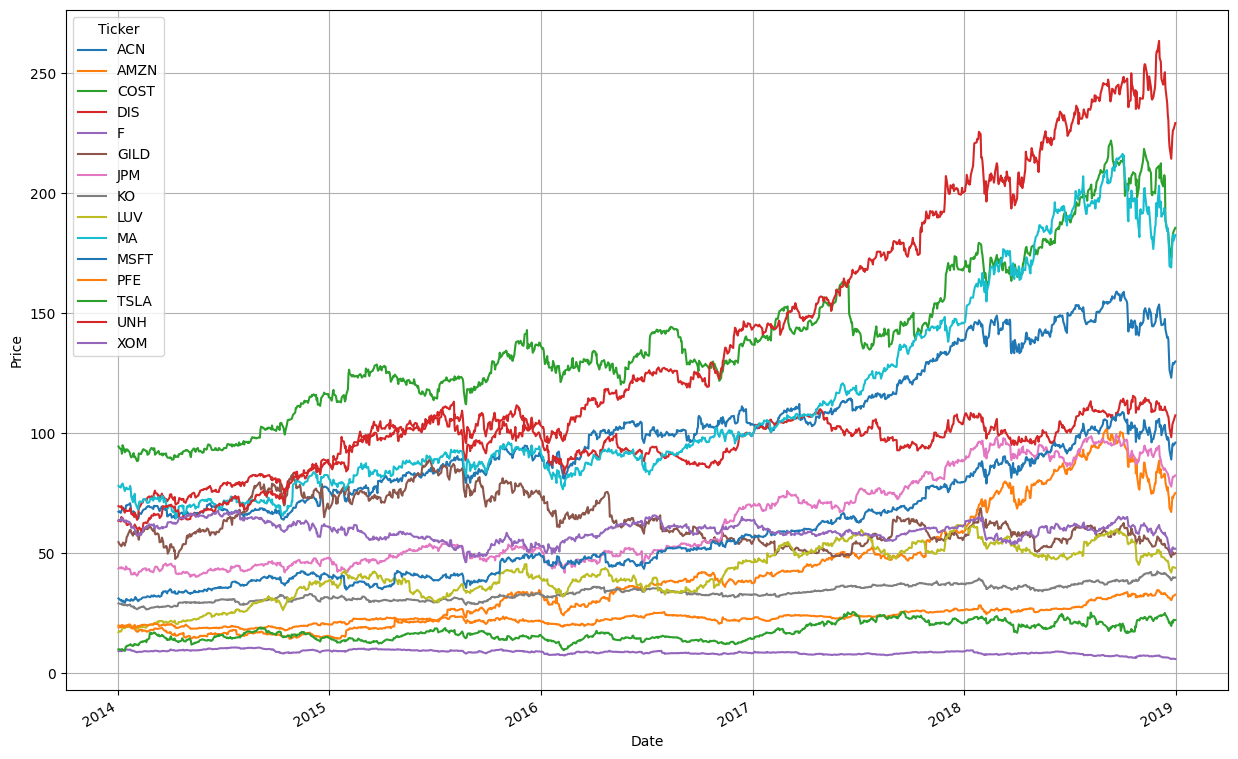

In [21]:
prices.plot(figsize=(15,10))
plt.ylabel("Price")
plt.grid(True)
plt.show()

In [22]:
df_return = (prices - prices.shift(1)) / prices.shift(1)
df_return.dropna(inplace=True)
df_return.head()

Ticker,ACN,AMZN,COST,DIS,F,GILD,JPM,KO,LUV,MA,MSFT,PFE,TSLA,UNH,XOM
Date,,,,,,,,,,,,,,,
2014-01-03,0.003328,-0.003845,-0.004414,-0.002098,0.004534,-0.011834,0.007730,-0.004918,0.028602,-0.003992,-0.006728,0.001970,-0.003598,0.007107,-0.002406
2014-01-06,-0.010565,-0.007088,-0.007588,-0.003810,0.004513,-0.014532,0.005796,-0.004696,-0.013903,-0.004959,-0.021132,0.000983,-0.017117,-0.011452,0.001507
2014-01-07,0.012168,0.011178,-0.004639,0.006858,-0.012837,-0.006281,-0.011526,0.002980,0.019843,0.013930,0.007750,0.006219,0.016054,0.030577,0.014149
2014-01-08,0.007728,0.009773,-0.015622,-0.014671,0.010403,0.009343,0.009431,-0.011142,0.033282,-0.000299,-0.017852,0.006831,0.012855,-0.011633,-0.003265
2014-01-09,0.009738,-0.002264,0.039105,-0.004254,0.019305,0.011434,-0.001868,-0.005258,0.028742,0.008078,-0.006432,-0.000646,-0.024788,0.006083,-0.009728


In [23]:
return_vec = df_return.values.T
print(np.shape(return_vec))

(15, 1257)


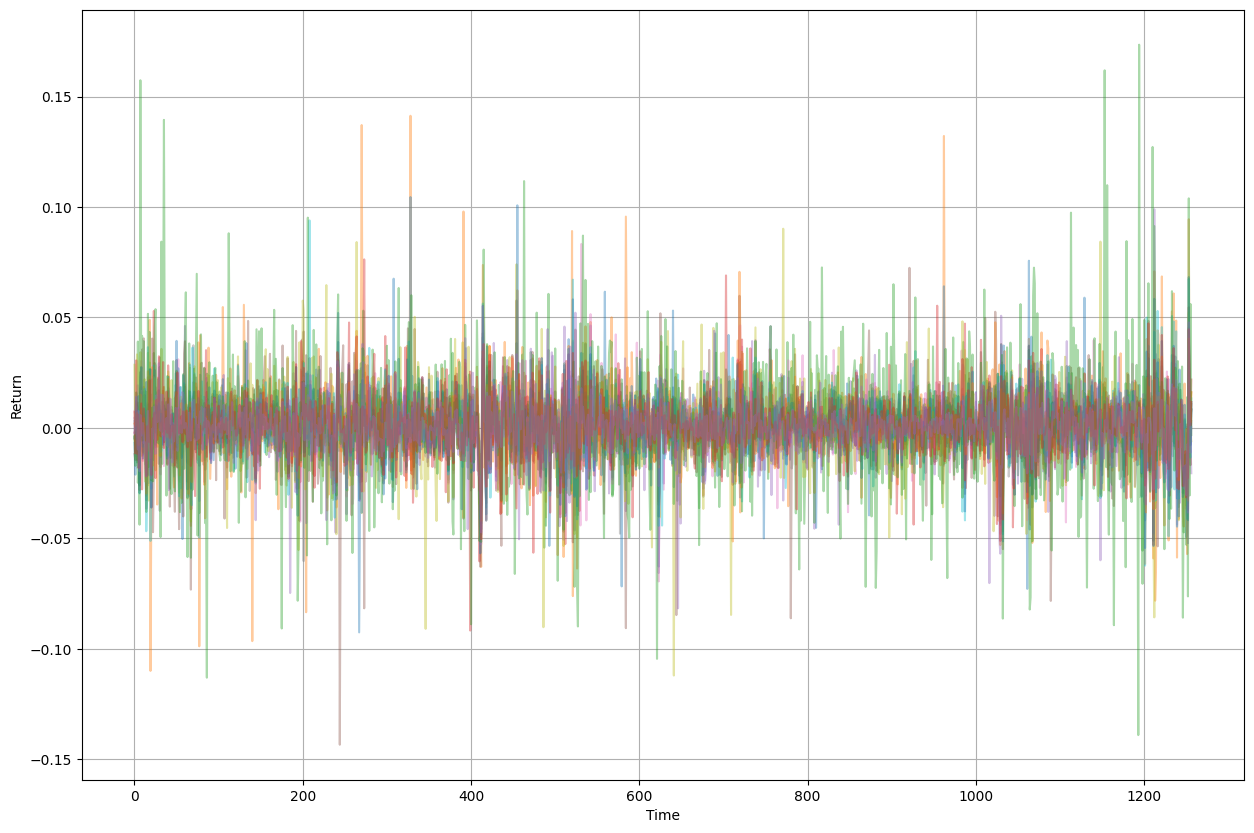

In [24]:
plt.figure(figsize=(15,10))
plt.plot(return_vec.T, alpha=.4)
plt.xlabel('Time')
plt.ylabel('Return')
plt.grid(True)
plt.show()

In [25]:
n_portfolios = 500
means, stds = np.column_stack([
    random_portfolio(return_vec)
    for _ in range(n_portfolios)
])
sharpes = means / np.sqrt(stds)

In [26]:
# Define a formatter function to format ticks as percentages
def percent_formatter(x, pos):
    return f'{x*100:.2f}%'

from matplotlib.ticker import FuncFormatter

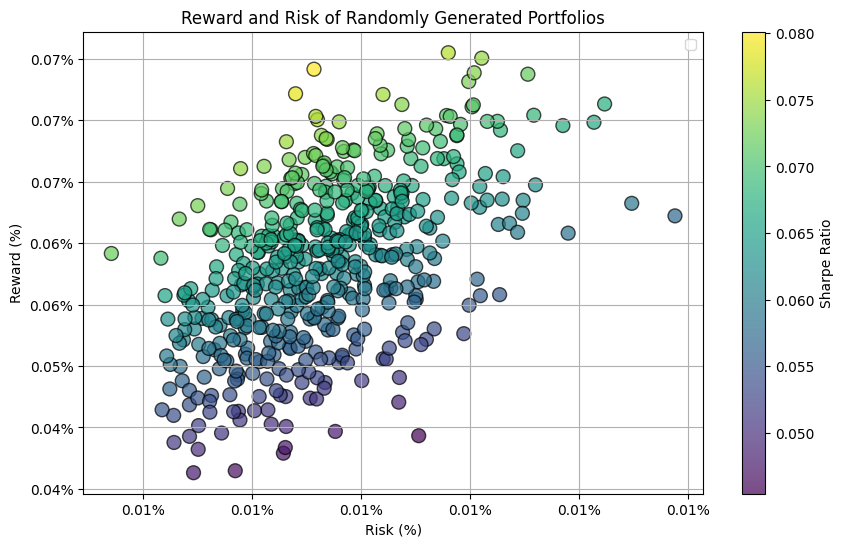

In [27]:
# Create the scatter plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(stds, means, c=sharpes, cmap='viridis', edgecolor='k', s=100, alpha=0.7)

# Apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(FuncFormatter(percent_formatter))
plt.gca().yaxis.set_major_formatter(FuncFormatter(percent_formatter))

# Add labels and title
plt.xlabel('Risk (%)')
plt.ylabel('Reward (%)')
plt.title('Reward and Risk of Randomly Generated Portfolios')

# Add a colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Sharpe Ratio')

# Show the plot
plt.legend()
plt.grid(True)
plt.show()

In [28]:
np.shape(return_vec)

(15, 1257)

In [29]:
rewards, risks, sharpes_optim, portfolios = optimal_portfolio(return_vec)

(100,)
Time to solve: 0.0071 seconds
(100, 15, 1)
(100,)
(100,)
(100,)


In [30]:
sharpes.max()

0.08012130746169693

In [31]:
sharpes_optim.max()

0.09773618400915296

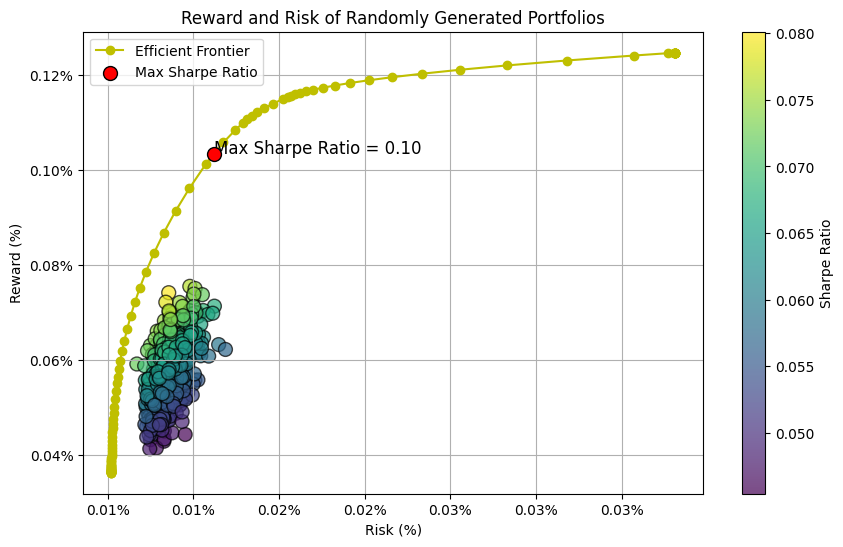

In [32]:
# Create the scatter plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(stds, means, c=sharpes, cmap='viridis', edgecolor='k', s=100, alpha=0.7)
plt.plot(risks, rewards, 'y-o', label='Efficient Frontier')

# Apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(FuncFormatter(percent_formatter))
plt.gca().yaxis.set_major_formatter(FuncFormatter(percent_formatter))

# Add labels and title
plt.xlabel('Risk (%)')
plt.ylabel('Reward (%)')
plt.title('Reward and Risk of Randomly Generated Portfolios')

# Add a colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Sharpe Ratio')

# Find the index of the maximum Sharpe ratio
max_sharpe_idx = np.argmax(sharpes_optim)
max_sharpe_risks = risks[max_sharpe_idx]
max_sharpe_returns = rewards[max_sharpe_idx]
max_sharpe_value = sharpes_optim[max_sharpe_idx]

# Highlight the point with the maximum Sharpe ratio
plt.scatter(max_sharpe_risks, max_sharpe_returns, color='red', s=100, edgecolor='k', zorder=5, label='Max Sharpe Ratio')

# Add annotation for the highlighted point
plt.annotate(
    f'Max Sharpe Ratio = {max_sharpe_value:.2f}',
    xy=(max_sharpe_risks, max_sharpe_returns),
    fontsize=12
)

# Show the plot
plt.legend()
plt.grid(True)
plt.show()

## **4. evaluation**

In [33]:
portfolios_optim = np.array(portfolios[max_sharpe_idx]).T
print(np.shape(portfolios_optim))

(1, 15)


In [34]:
prices_future = yf.download(tickers, start="2019-01-01", end="2020-01-01")["Adj Close"].dropna(how="all")

[*********************100%%**********************]  15 of 15 completed


In [35]:
df_return_future = (prices_future - prices_future.shift(1)) / prices_future.shift(1)
df_return_future.dropna(inplace=True)
return_vec_future = df_return_future.values.T

p = np.asmatrix(np.mean(return_vec_future, axis=1))
w = np.asmatrix(portfolios_optim)
C = np.asmatrix(np.cov(return_vec_future))

reward = w * p.T
risk = w * C * w.T
sharpe_ratio = reward / np.sqrt(risk)

In [36]:
predict = np.dot(portfolios_optim, return_vec_future)[0]

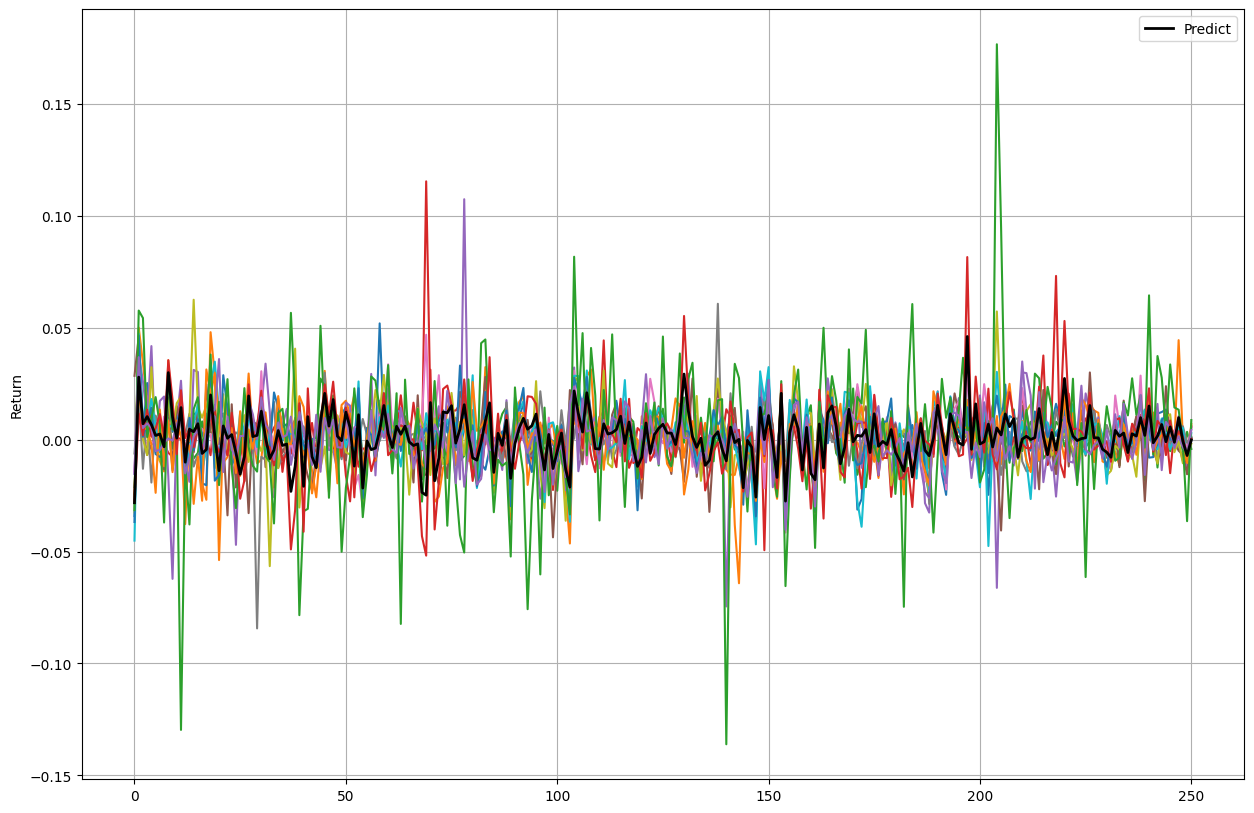

In [37]:
# Plot df_return_future with each column as a separate line
plt.figure(figsize=(15, 10))
plt.plot(df_return_future.values)

# Overlay predict with a black line
plt.plot(predict, color='black', linewidth=2, label='Predict')

# Add labels, grid, and legend
plt.ylabel("Return")
plt.grid(True)
plt.legend()

# Show plot
plt.show()

## **5. separable quadratic programming**

In [38]:
def separable_optimal_portfolio(returns):
    n = returns.shape[0]
    T = returns.shape[1]
    # returns = np.asmatrix(returns)

    N = 100
    mus = [10**(5.0 * t/N - 1.0) for t in range(N)]
    print(np.shape(mus))

    # Convert to cvxopt matrices
    # S = opt.matrix(np.cov(returns))
    # pbar = opt.matrix(np.mean(returns, axis=1))

    S_matrix = np.zeros((n + T, n + T))
    np.fill_diagonal(S_matrix[n:, n:], 1 / T)
    S = opt.matrix(S_matrix)
    pbar = opt.matrix(np.concatenate((np.mean(returns, axis=1), np.zeros(T))))

    # Create constraint matrices
    # G = -opt.matrix(np.eye(n))   # negative n x n identity matrix
    # h = opt.matrix(0.0, (n, 1))
    # A = opt.matrix(1.0, (1, n))
    # b = opt.matrix(1.0)

    G_matrix = np.block([
        [-np.eye(n), np.zeros((n, T))],
        [np.zeros((T, n)), np.zeros((T, T))]
    ])
    G = opt.matrix(G_matrix)
    h = opt.matrix(0.0, (n + T, 1))

    return_T = np.array(returns.T)
    mean_returns_reshaped = return_T.mean(axis=1)[:, np.newaxis]
    return_T_hat = return_T - mean_returns_reshaped
    A_matrix = np.block([
        [np.ones((1, n)), np.zeros((1, T))],
        [return_T_hat, -np.eye(T)]
    ])
    b_vector = np.zeros(T + 1)
    b_vector[0] = 1
    A = opt.matrix(A_matrix)
    b = opt.matrix(b_vector)

    # Calculate efficient frontier weights using quadratic programming
    import time
    start_time = time.time()  # Start timing
    print("Start")
    portfolios = [solvers.qp(mu*S, -pbar, G, h, A, b)['x']
                  for mu in mus]
    end_time = time.time()  # End timing
    elapsed_time = (end_time - start_time) / N  # Calculate elapsed time
    print(f"Time to solve: {elapsed_time:.4f} seconds")
    print(np.shape(portfolios))

    ## CALCULATE RISKS AND REWARDS FS FRONTIER
    rewards = [blas.dot(pbar, x) for x in portfolios]
    # risks = [np.sqrt(blas.dot(x, S*x)) for x in portfolios]
    risks = [blas.dot(x, S*x) for x in portfolios]
    print(np.shape(rewards))
    print(np.shape(risks))

    sharpes = rewards / np.sqrt(risks)
    print(np.shape(sharpes))

    # ## CALCULATE THE 2ND DEGREE POLYNOMIAL OF THE FRONTIER CURVE
    # m1 = np.polyfit(rewards, risks, 2)
    # x1 = np.sqrt(m1[2] / m1[0])

    # # CALCULATE THE OPTIMAL PORTFOLIO
    # wt = solvers.qp(opt.matrix(x1 * S), -pbar, G, h, A, b)['x']

    # return np.asarray(wt), rewards, risks
    return rewards, risks, sharpes, portfolios

In [39]:
import bs4 as bs
import requests

# Read and print the stock tickers that make up S&P500
tickers = pd.read_html(
    'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies')[0]

In [40]:
np.shape(tickers.Symbol.to_list())

(503,)

In [41]:
# Get the data for this tickers from yahoo finance
df = yf.download(tickers.Symbol.to_list(), '2023-01-01', '2023-02-01', auto_adjust=True)

[**                     5%%                      ]  23 of 503 completed

$BF.B: possibly delisted; No price data found  (1d 2023-01-01 -> 2023-02-01)


[*********************100%%**********************]  503 of 503 completed
ERROR:yfinance:
7 Failed downloads:
ERROR:yfinance:['VLTO', 'SW', 'KVUE', 'SOLV', 'GEV']: YFChartError("%ticker%: Data doesn't exist for startDate = 1672549200, endDate = 1675227600")
ERROR:yfinance:['BF.B']: YFPricesMissingError('$%ticker%: possibly delisted; No price data found  (1d 2023-01-01 -> 2023-02-01)')
ERROR:yfinance:['BRK.B']: YFTzMissingError('$%ticker%: possibly delisted; No timezone found')


In [42]:
prices_test = df["Close"].dropna(axis=1)
df_return_test = (prices_test - prices_test.shift(1)) / prices_test.shift(1)
df_return_test.dropna(inplace=True)
return_vec_test = df_return_test.values.T
print(return_vec_test.shape)

(496, 19)


In [43]:
n_portfolios = 500
means, stds = np.column_stack([
    random_portfolio(return_vec_test)
    for _ in range(n_portfolios)
])
sharpes = means / np.sqrt(stds)

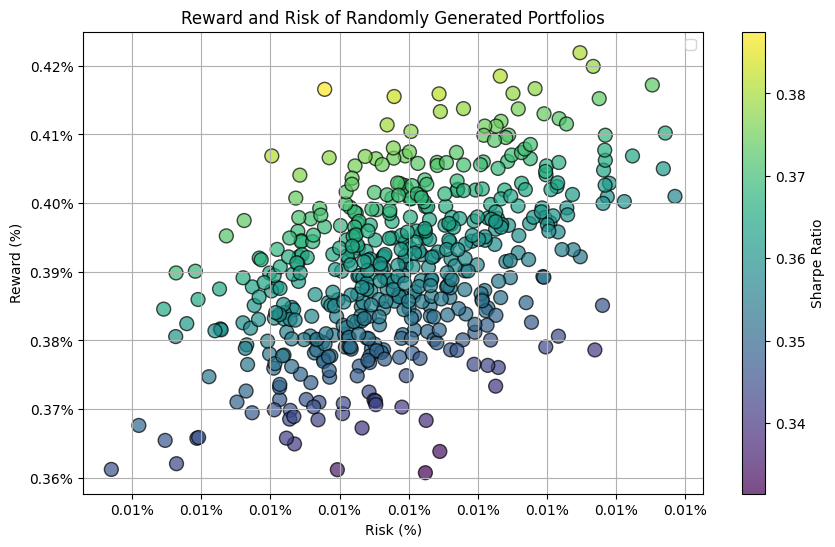

In [44]:
# Create the scatter plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(stds, means, c=sharpes, cmap='viridis', edgecolor='k', s=100, alpha=0.7)

# Apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(FuncFormatter(percent_formatter))
plt.gca().yaxis.set_major_formatter(FuncFormatter(percent_formatter))

# Add labels and title
plt.xlabel('Risk (%)')
plt.ylabel('Reward (%)')
plt.title('Reward and Risk of Randomly Generated Portfolios')

# Add a colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Sharpe Ratio')

# Show the plot
plt.legend()
plt.grid(True)
plt.show()

In [45]:
rewards, risks, sharpes_optim, portfolio = optimal_portfolio(return_vec_test)

(100,)
Time to solve: 0.1690 seconds
(100, 496, 1)
(100,)
(100,)
(100,)


In [46]:
sharpes_optim.max()

1.2891172967629907

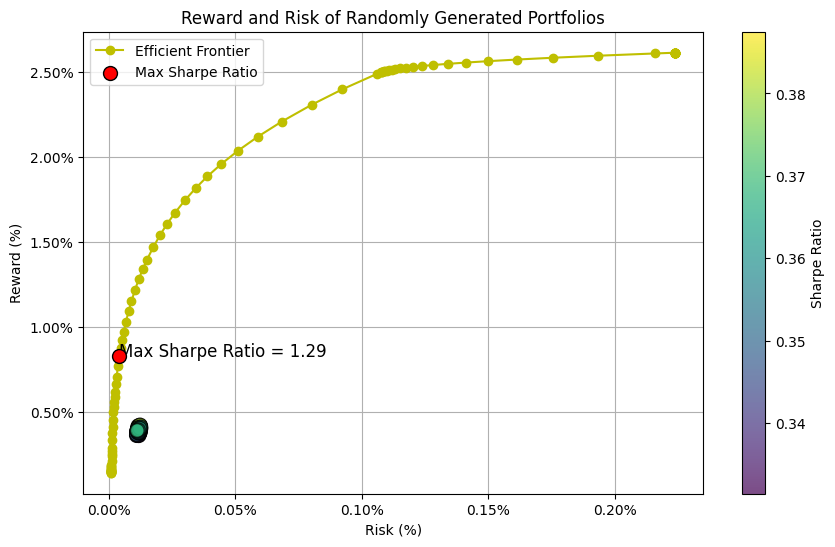

In [47]:
# Create the scatter plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(stds, means, c=sharpes, cmap='viridis', edgecolor='k', s=100, alpha=0.7)
plt.plot(risks, rewards, 'y-o', label='Efficient Frontier')

# Apply the formatter to the x-axis
plt.gca().xaxis.set_major_formatter(FuncFormatter(percent_formatter))
plt.gca().yaxis.set_major_formatter(FuncFormatter(percent_formatter))

# Add labels and title
plt.xlabel('Risk (%)')
plt.ylabel('Reward (%)')
plt.title('Reward and Risk of Randomly Generated Portfolios')

# Add a colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Sharpe Ratio')


# Find the index of the maximum Sharpe ratio
max_sharpe_idx = np.argmax(sharpes_optim)
max_sharpe_risks = risks[max_sharpe_idx]
max_sharpe_returns = rewards[max_sharpe_idx]
max_sharpe_value = sharpes_optim[max_sharpe_idx]

# Highlight the point with the maximum Sharpe ratio
plt.scatter(max_sharpe_risks, max_sharpe_returns, color='red', s=100, edgecolor='k', zorder=5, label='Max Sharpe Ratio')

# Add annotation for the highlighted point
plt.annotate(
    f'Max Sharpe Ratio = {max_sharpe_value:.2f}',
    xy=(max_sharpe_risks, max_sharpe_returns),
    fontsize=12
)

# Show the plot
plt.legend()
plt.grid(True)
plt.show()

In [48]:
# separable_rewards,  separable_risks,  separable_sharpes_optim = separable_optimal_portfolio(return_vec_test)

In [49]:
# separable_sharpes_optim.max()

In [50]:
# # Create the scatter plot
# plt.figure(figsize=(10, 6))
# scatter = plt.scatter(stds, means, c=sharpes, cmap='viridis', edgecolor='k', s=100, alpha=0.7)
# plt.plot(separable_risks, separable_rewards, 'y-o', label='Efficient Frontier')

# # Apply the formatter to the x-axis
# plt.gca().xaxis.set_major_formatter(FuncFormatter(percent_formatter))
# plt.gca().yaxis.set_major_formatter(FuncFormatter(percent_formatter))

# # Add labels and title
# plt.xlabel('Risk (%)')
# plt.ylabel('Reward (%)')
# plt.title('Reward and Risk of Randomly Generated Portfolios')

# # Add a colorbar
# cbar = plt.colorbar(scatter)
# cbar.set_label('Sharpe Ratio')


# # Find the index of the maximum Sharpe ratio
# max_sharpe_idx = np.argmax(separable_sharpes_optim)
# max_sharpe_risks = separable_risks[max_sharpe_idx]
# max_sharpe_returns = separable_rewards[max_sharpe_idx]
# max_sharpe_value = separable_sharpes_optim[max_sharpe_idx]

# # Highlight the point with the maximum Sharpe ratio
# plt.scatter(max_sharpe_risks, max_sharpe_returns, color='red', s=100, edgecolor='k', zorder=5, label='Max Sharpe Ratio')

# # Add annotation for the highlighted point
# plt.annotate(
#     f'Max Sharpe Ratio = {max_sharpe_value:.2f}',
#     xy=(max_sharpe_risks, max_sharpe_returns),
#     fontsize=12
# )

# # Show the plot
# plt.legend()
# plt.grid(True)
# plt.show()